# Notebook 02 — NumPy, Pandas et un premier signal

**Objectif :** calculer vite sur des milliers de mesures, et construire un signal dont on connaît tout.

**Pourquoi NumPy ?** Une liste Python est souple mais lente pour le calcul. Un tableau NumPy (`ndarray`) contient des nombres du même type et applique une opération à **tous** ses éléments d'un coup.

In [1]:
import numpy as np
liste = [1.0, 2.0, 3.0]
tableau = np.array([1.0, 2.0, 3.0])
print(liste * 2)      # liste : répète la liste !
print(tableau * 2)    # ndarray : multiplie chaque nombre
print(tableau.dtype, tableau.shape)

[1.0, 2.0, 3.0, 1.0, 2.0, 3.0]
[2. 4. 6.]
float64 (3,)


## 1. Construire un signal à fréquence connue

On simule 2 secondes d'un capteur qui mesure 100 fois par seconde (**fs = 100 Hz**) un mouvement sinusoïdal de **1,5 Hz** et d'amplitude **0,3 g**.

- t[n] = n / fs : instant de la mesure n, en secondes ;
- x[n] = A · sin(2π · f · t[n]) : valeur mesurée, en g.

In [2]:
fs = 100.0          # Hz : mesures par seconde
duree = 2.0         # s
f = 1.5             # Hz : fréquence du mouvement
A = 0.3             # g  : amplitude
n = np.arange(int(fs * duree))   # 0, 1, ..., 199
t = n / fs
x = A * np.sin(2 * np.pi * f * t)
print(len(t), "mesures ; intervalle", (t[1] - t[0]) * 1000, "ms")

200 mesures ; intervalle 10.0 ms


## 2. Ajouter un bruit reproductible

Un vrai capteur est bruité. On ajoute un bruit gaussien d'écart-type 0,02 g. Le générateur reçoit une **graine** (*seed*) : avec la même graine, on obtient exactement le même bruit, ce qui rend l'expérience reproductible.

In [3]:
rng = np.random.default_rng(2027)
bruit = rng.normal(0.0, 0.02, size=len(t))
x_bruite = x + bruit
print(x_bruite[:5].round(4))

[0.0022 0.0266 0.0401 0.0407 0.1347]


## 3. Moyenne, écart-type et RMS

- moyenne = (1/N) Σ x[n]
- écart-type = √((1/N) Σ (x[n] − moyenne)²)
- RMS = √((1/N) Σ x[n]²)

Pour une sinusoïde pure d'amplitude A sur un nombre entier de périodes, RMS = A / √2.

In [4]:
print("moyenne    :", x_bruite.mean().round(4), "g")
print("écart-type :", x_bruite.std().round(4), "g")
print("RMS        :", np.sqrt(np.mean(x_bruite**2)).round(4), "g")
print("A / √2     :", round(A / np.sqrt(2), 4), "g (sinusoïde pure, 3 périodes entières)")

moyenne    : 0.0005 g
écart-type : 0.2128 g
RMS        : 0.2128 g
A / √2     : 0.2121 g (sinusoïde pure, 3 périodes entières)


## 4. Tracer

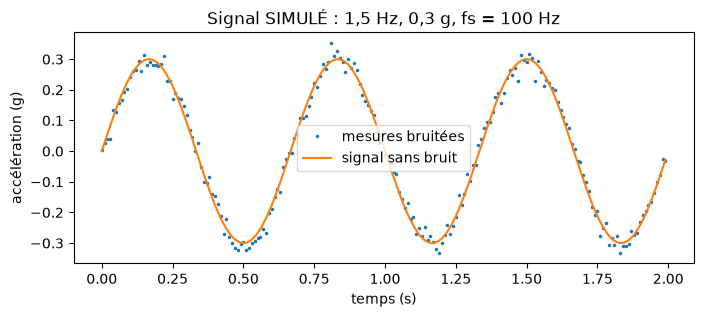

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, x_bruite, ".", ms=3, label="mesures bruitées")
ax.plot(t, x, label="signal sans bruit")
ax.set_xlabel("temps (s)"); ax.set_ylabel("accélération (g)"); ax.legend()
ax.set_title("Signal SIMULÉ : 1,5 Hz, 0,3 g, fs = 100 Hz")
plt.show()

## 5. Pandas : un tableau avec des noms de colonnes

Les fichiers CSV du cours se lisent avec Pandas. Un `DataFrame` est un tableau dont chaque colonne a un nom.

In [6]:
import pandas as pd
df = pd.DataFrame({"t_s": t, "ax_g": x_bruite})
print(df.head())
print(df.describe().round(4))

    t_s      ax_g
0  0.00  0.002218
1  0.01  0.026557
2  0.02  0.040131
3  0.03  0.040654
4  0.04  0.134674
            t_s      ax_g
count  200.0000  200.0000
mean     0.9950    0.0005
std      0.5788    0.2134
min      0.0000   -0.3324
25%      0.4975   -0.2076
50%      0.9950    0.0043
75%      1.4925    0.1997
max      1.9900    0.3528


> **Question.** Que signifie « g » ? Pourquoi un accéléromètre posé sur une table mesure-t-il environ 1 g sur un axe, alors qu'il ne bouge pas ?